# Assignment 1 — Data Acquisition, Text Processing & Cleaning
**Project:** emotion classification of Reddit comments (GoEmotions)  
**Team:** `<team name>` · **Members:** `<names + roll numbers>`

Run order: this notebook imports the same functions that `python -m src.run_phase1` uses, so results here equal the saved cleaned CSV.

In [1]:
import sys, re, json, collections
sys.path.append('..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.max_colwidth', 110)

from src.data_loader import load_goemotions
from src import patterns as P
from src.cleaning import (clean_text, clean_tokens, raw_tokens, normalize_unicode, remove_noise,
                          expand_contractions, collapse_elongation, extract_raw_features, STOP_WORDS)

## Task 1 — Dataset & environment
GoEmotions (Demszky et al., 2020): 58k English Reddit comments labelled with 27 emotions + neutral. Licence: Apache 2.0. Prediction target (Phase 3): the emotion label.  
We keep comments with exactly **one** emotion label so the target is a clean multi-class label.

In [2]:
df = load_goemotions(single_label_only=True)
print('single-label comments:', len(df))
print(df.split.value_counts().to_dict())
df.head()

single-label comments: 45446
{'train': 36308, 'test': 4590, 'dev': 4548}


,id,text,label,split
0,eebbqej,My favourite food is anything I didn't have to cook myself.,neutral,train
1,ed00q6i,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actuall...",neutral,train
2,eezlygj,WHY THE FUCK IS BAYLESS ISOING,anger,train
3,ed7ypvh,To make her feel threatened,fear,train
4,ed0bdzj,Dirty Southern Wankers,annoyance,train


## Task 2 — Exploration & basic statistics

documents            : 45446
avg words / document : 12.6 | median 12.0 | max 32
number of classes    : 28
label
neutral           16021
admiration         3384
gratitude          2378
approval           2367
amusement          2046
annoyance          1809
disapproval        1809
love               1760
curiosity          1729
anger              1265
optimism           1087
confusion          1057
joy                1052
sadness            1003
surprise            902
disappointment      888
caring              831
realization         749
disgust             635
excitement          619
fear                553
desire              497
remorse             437
embarrassment       246
nervousness         105
relief              103
pride                67
grief                47


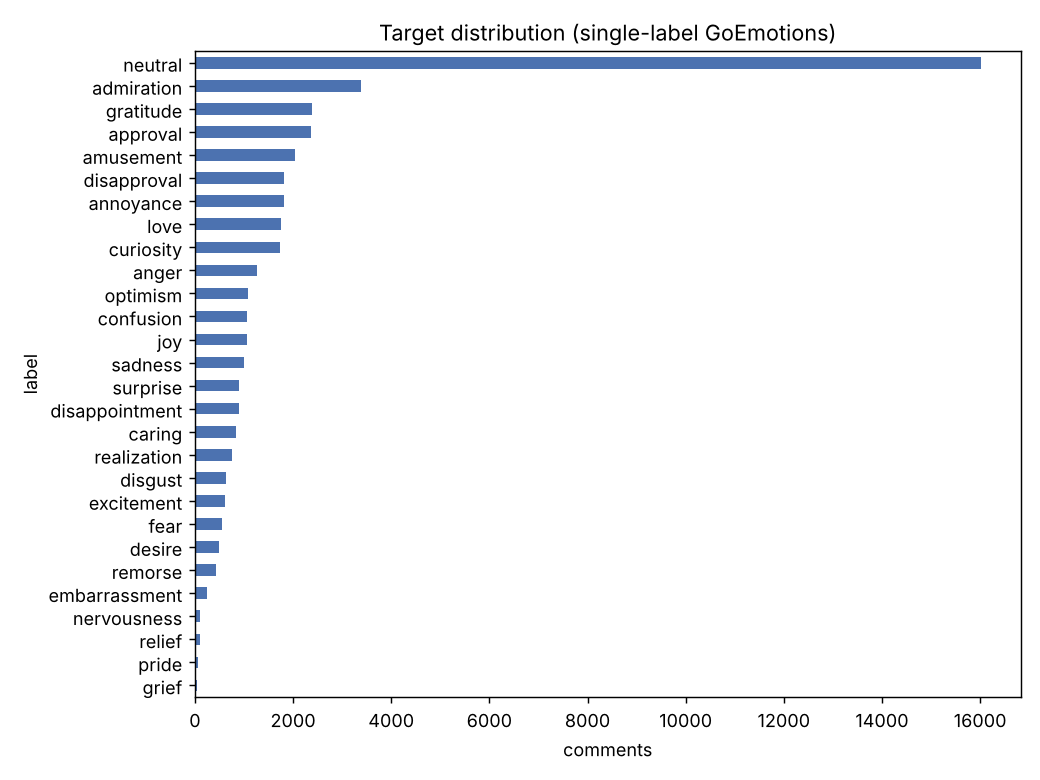

In [3]:
df['n_words'] = df.text.str.split().str.len()
print('documents            :', len(df))
print('avg words / document :', round(df.n_words.mean(), 2), '| median', df.n_words.median(), '| max', df.n_words.max())
print('number of classes    :', df.label.nunique())
dist = df.label.value_counts()
print(dist.to_string())
fig, ax = plt.subplots(figsize=(8,6)); dist.sort_values().plot.barh(ax=ax, color='#4c72b0')
ax.set_title('Target distribution (single-label GoEmotions)'); ax.set_xlabel('comments'); plt.tight_layout()
plt.savefig('../figures/label_distribution.png', dpi=130); plt.close()
display(Image('../figures/label_distribution.png'))

tokens (running words): 127160
types  (vocabulary)   : 12238
type/token ratio      : 0.0962
hapax legomena (freq 1): 6718 = 54.9% of types
[('the', 4168), ('i', 3832), ('to', 2825), ('a', 2793), ('you', 2243), ('and', 2098), ('it', 1989), ('that', 1964), ('is', 1867), ('name', 1769), ('of', 1707), ('this', 1429), ('in', 1385), ('for', 1285), ('was', 890)]


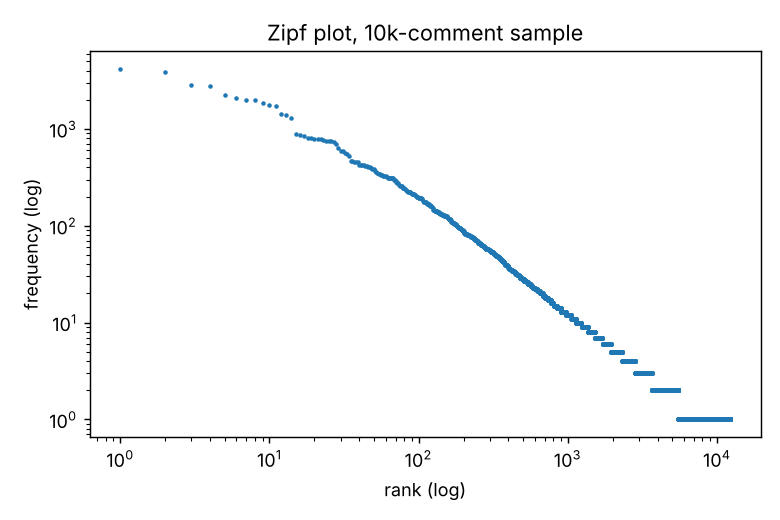

In [4]:
# tokens vs types on a 10,000-comment sample (simple lower-cased word tokens)
sample = df.sample(10000, random_state=42)
toks = [w for t in sample.text for w in re.findall(r"[a-z']+", t.lower())]
cnt = collections.Counter(toks)
print('tokens (running words):', len(toks))
print('types  (vocabulary)   :', len(cnt))
print('type/token ratio      :', round(len(cnt)/len(toks), 4))
hapax = sum(1 for c in cnt.values() if c == 1)
print(f'hapax legomena (freq 1): {hapax} = {100*hapax/len(cnt):.1f}% of types')
top = cnt.most_common(15); print(top)

freqs = np.array(sorted(cnt.values(), reverse=True)); ranks = np.arange(1, len(freqs)+1)
fig, ax = plt.subplots(figsize=(6,4)); ax.loglog(ranks, freqs, '.', ms=3)
ax.set_xlabel('rank (log)'); ax.set_ylabel('frequency (log)'); ax.set_title('Zipf plot, 10k-comment sample'); plt.tight_layout()
plt.savefig('../figures/zipf.png', dpi=130); plt.close(); display(Image('../figures/zipf.png'))

**Zipf / long tail.** The log-log rank–frequency plot is close to a straight line, as Zipf's law predicts: a handful of words ('i', 'the', 'you', 'to') dominate the running text while the majority of types are rare — about 55% of the vocabulary types occur only once (hapax legomena). Note that `name` is the 10th most frequent word only because of the `[NAME]` placeholder — a data artefact that our cleaning removes. This long tail matters later: rare words get weak embeddings (Assignment 2) and motivate `min_count`/`min_df` thresholds.

In [5]:
examples = {
 'ALL CAPS shouting': df.text[df.text.str.contains(P.ALLCAPS_WORD)].head(1).tolist(),
 'anonymisation placeholders': df.text[df.text.str.contains(P.PLACEHOLDER)].head(1).tolist(),
 'curly apostrophes (Unicode)': df.text[df.text.str.contains('\u2019')].head(1).tolist(),
 'emoji': df.text[df.text.str.contains(r'[\U0001F300-\U0001FAFF]')].head(1).tolist(),
 'elongation': df.text[df.text.str.contains(r'[a-z]([a-z])\1{2,}')].head(1).tolist(),
 'subreddit mention + markdown': df.text[df.text.str.contains(P.SUBREDDIT_USER)].head(1).tolist(),
 'mixed case (sarcasm style)': df.text[df.text.str.contains('OmG')].head(1).tolist(),
}
for k, v in examples.items(): print(f'[{k}]\n   {v[0] if v else "-"}\n')

[ALL CAPS shouting]
   WHY THE FUCK IS BAYLESS ISOING

[anonymisation placeholders]
   [NAME] - same fucking problem, slightly better command of the English language.

[curly apostrophes (Unicode)]
   Demographics? I don’t know anybody under 35 who has cable tv.

[emoji]
   Yes I heard abt the f bombs! That has to be why. Thanks for your reply:) until then hubby and I will anxiously wait 😝

[elongation]
   Yeahhhh no, you're banned for this whole convo.

[subreddit mention + markdown]
   Ask over at r/NewTubers

[mixed case (sarcasm style)]
   OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe PlAyOfFs! Dumbass Broncos fans circa December 2015.



## Task 3 — Tokenization & regular expressions

In [6]:
import spacy, nltk
from nltk.tokenize import word_tokenize, TweetTokenizer
nlp = spacy.load('en_core_web_sm', disable=['parser','ner','lemmatizer'])
regex_tok = lambda s: re.findall(r"[A-Za-z]+(?:'[a-z]+)?|\d+|[^\w\s]", s)
tw = TweetTokenizer()
sents = ["I can't believe it's not butter!!! sooo mad 😡",
         "OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe PlAyOfFs!",
         "My favourite food is anything I didn't have to cook myself.",
         "Thanks :) see you at r/hockey, it's a well-known sub #70"]
for s in sents:
    print('TEXT     :', s)
    print('split()  :', s.split())
    print('regex    :', regex_tok(s))
    print('NLTK     :', word_tokenize(s))
    print('Tweet    :', tw.tokenize(s))
    print('spaCy    :', [t.text for t in nlp(s)], '\n')

TEXT     : I can't believe it's not butter!!! sooo mad 😡
split()  : ['I', "can't", 'believe', "it's", 'not', 'butter!!!', 'sooo', 'mad', '😡']
regex    : ['I', "can't", 'believe', "it's", 'not', 'butter', '!', '!', '!', 'sooo', 'mad', '😡']
NLTK     : ['I', 'ca', "n't", 'believe', 'it', "'s", 'not', 'butter', '!', '!', '!', 'sooo', 'mad', '😡']
Tweet    : ['I', "can't", 'believe', "it's", 'not', 'butter', '!', '!', '!', 'sooo', 'mad', '😡']
spaCy    : ['I', 'ca', "n't", 'believe', 'it', "'s", 'not', 'butter', '!', '!', '!', 'sooo', 'mad', '😡'] 

TEXT     : OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe PlAyOfFs!
split()  : ['OmG', 'pEyToN', "iSn'T", 'gOoD', 'eNoUgH', 'tO', 'hElP', 'uS', 'iN', 'tHe', 'PlAyOfFs!']
regex    : ['OmG', 'pEyToN', 'iSn', "'", 'T', 'gOoD', 'eNoUgH', 'tO', 'hElP', 'uS', 'iN', 'tHe', 'PlAyOfFs', '!']
NLTK     : ['OmG', 'pEyToN', "iSn'T", 'gOoD', 'eNoUgH', 'tO', 'hElP', 'uS', 'iN', 'tHe', 'PlAyOfFs', '!']
Tweet    : ['OmG', 'pEyToN', "iSn'T", 'gOoD', 'eNoUgH', 'tO', 

**Comparison (from the outputs above).** `split()` leaves punctuation glued to words (`'myself.'`, `'butter!!!'`, `'r/hockey,'`). My regex tokenizer keeps simple contractions as one token but splits `!!!` into three tokens, breaks `well-known` and `r/hockey` apart, and fails on odd-case contractions (`iSn'T` → `iSn`, `'`, `T`) because it expects a lowercase suffix. NLTK `word_tokenize` splits contractions into `did` + `n't` (handy for negation), keeps `well-known` together, but breaks the emoticon `:)` into `:` and `)`. `TweetTokenizer` keeps `:)`, `#70` and emoji intact — the best fit for social text — but splits `r/hockey`. spaCy behaves like NLTK on contractions, keeps `:)`, and splits hyphens and hashtags.

**Challenges seen in our data:** (1) contractions and negation: `can't`, `didn't` must become `not` or sentiment flips; (2) emoji and emoticons carry emotion but are not words, and tokenizers disagree on them; (3) elongation (`sooo`) and random capitalisation (`OmG pEyToN`) create many rare types of the same word.

In [7]:
patterns = {
 '1 placeholder  [NAME]/[RELIGION]': P.PLACEHOLDER,
 '2 subreddit/user mention': P.SUBREDDIT_USER,
 '3 elongation (3+ same char)': P.ELONGATION,
 '4 ALL-CAPS word': P.ALLCAPS_WORD,
 '5 markdown emphasis': P.MARKDOWN,
 '6 number / price': P.NUMBER,
 '7 URL': P.URL, '8 e-mail': P.EMAIL,
}
for name, pat in patterns.items():
    hits = df.text[df.text.str.contains(pat)]
    ex = pat.search(hits.iloc[0]).group(0) if len(hits) else '-'
    print(f'{name:36s} pattern={pat.pattern!r:42s} comments={len(hits):6d}  e.g. {ex!r}')

1 placeholder  [NAME]/[RELIGION]     pattern='\\[(?:NAME|RELIGION)\\]'                  comments=  6581  e.g. '[NAME]'
2 subreddit/user mention             pattern='(?<!\\w)/?(?:r|u)/\\w+'                   comments=   302  e.g. 'r/NewTubers'
3 elongation (3+ same char)          pattern='(\\w)\\1{2,}'                             comments=   750  e.g. 'TTT'


4 ALL-CAPS word                      pattern='\\b[A-Z]{3,}\\b'                          comments=  9091  e.g. 'WHY'


5 markdown emphasis                  pattern='\\*+|_{2,}|~~|`'                          comments=   774  e.g. '**'
6 number / price                     pattern='\\$?\\d[\\d,.]*'                          comments=  4020  e.g. '2015.'
7 URL                                pattern='(?:https?://|www\\.)\\S+'                 comments=     0  e.g. '-'


8 e-mail                             pattern='\\b[\\w.+-]+@[\\w-]+\\.[\\w.-]+\\b'       comments=     0  e.g. '-'


**Pattern explanations**
1. `\[(?:NAME|RELIGION)\]` — literal square brackets (escaped) around one of two fixed words; marks anonymised text the authors inserted. Removed because it is an artefact, not user language.
2. `(?<!\w)/?(?:r|u)/\w+` — optional leading slash, `r` or `u`, slash, then word characters; the negative look-behind `(?<!\w)` prevents matching inside words like `chair/user`. Removes Reddit navigation noise.
3. `(\w)\1{2,}` — captures one character and requires it to repeat 2+ more times (back-reference `\1`); `sooooo` → `soo` after `re.sub(r'\1\1')`, so all spellings of the same elongated word collapse into one type.
4. `\b[A-Z]{3,}\b` — whole words of 3+ capital letters; counted as a *feature* (shouting ≈ anger) before lower-casing.
URL and e-mail patterns find **0** matches: the dataset is already anonymised — noted rather than assumed.

## Task 4 — Cleaning & normalization pipeline

**Order and justification** (one line each)

| # | Step | Why it is here for GoEmotions |
|---|---|---|
| 0 | Save raw features (ALL-CAPS count, `!` count) | capitalisation/punctuation signal anger/excitement; must be taken before they are destroyed |
| 1 | Unicode NFC + curly quotes → `'` | about 12% of comments use the curly `’`; without this `don’t` ≠ `don't` |
| 2 | Noise removal (placeholders, mentions, markdown, URLs); emoji → words | artefacts carry no emotion; emoji do, so they are kept as words |
| 3 | Expand contractions | turns `didn't` into `did not` so negation survives stop-word removal |
| 4 | Collapse elongation | `soooo`/`sooo` → one type |
| 5 | Lower-case | merges `Happy`/`happy`; safe because step 0 kept the caps signal |
| 6 | Tokenise (NLTK), drop tokens without letters | removes punctuation/number-only tokens |
| 7 | POS-tag the whole sentence | lemmatiser needs the part of speech |
| 8 | Stop-word removal with a **custom** list | NLTK list minus negations/intensifiers (`not`, `no`, `never`, `very`, `too`, `so`, …) |
| 9 | Lemmatise (WordNet, POS-aware) | see comparison below |

In [8]:
s = "I'm NOT happy!!! sooooo disappointed 😘 r/hockey **used** to be fun, [NAME] didn’t care"
steps = [('raw', s)]
t = normalize_unicode(s); steps.append(('1 unicode', t))
t = remove_noise(t);      steps.append(('2 noise', t))
t = expand_contractions(t); steps.append(('3 contractions', t))
t = collapse_elongation(t); steps.append(('4 elongation', t))
t = t.lower();            steps.append(('5 lower', t))
steps.append(('6-9 tokens → final', clean_tokens(s)))
for n, v in steps: print(f'{n:20s}', v)
print('\nraw features:', extract_raw_features(s))

raw                  I'm NOT happy!!! sooooo disappointed 😘 r/hockey **used** to be fun, [NAME] didn’t care
1 unicode            I'm NOT happy!!! sooooo disappointed 😘 r/hockey **used** to be fun, [NAME] didn't care
2 noise              I'm NOT happy!!! sooooo disappointed  face blowing a kiss     used  to be fun,   didn't care
3 contractions       I am NOT happy!!! sooooo disappointed  face blowing a kiss     used  to be fun,   did not care
4 elongation         I am NOT happy!!! soo disappointed  face blowing a kiss     used  to be fun,   did not care
5 lower              i am not happy!!! soo disappointed  face blowing a kiss     used  to be fun,   did not care
6-9 tokens → final   ['not', 'happy', 'soo', 'disappoint', 'face', 'blow', 'kiss', 'use', 'fun', 'not', 'care']

raw features: {'n_caps_words': 2, 'n_exclaim': 3, 'has_punct_run': 1}


In [9]:
# stop-word check: the list must not delete words the emotion task needs
needed = ['not','no','nor','never','very','too','so','but','against','without','neither','more','most']
print('negations/intensifiers still deleted by our list:', [w for w in needed if w in STOP_WORDS])
from nltk.corpus import stopwords
print('deleted by the default NLTK list but KEPT by ours:', sorted(set(stopwords.words('english')) & set(needed)))
print('\nexample: ', clean_text("This is not good and I never liked it"))

negations/intensifiers still deleted by our list: []
deleted by the default NLTK list but KEPT by ours: ['against', 'but', 'more', 'most', 'no', 'nor', 'not', 'so', 'too', 'very']

example:  not good never like


In [10]:
# stemming vs lemmatisation on emotion words (ONE is used in the pipeline: lemmatisation)
from nltk.stem import PorterStemmer, WordNetLemmatizer
ps, wl = PorterStemmer(), WordNetLemmatizer()
rows = []
for w, pos in [('happiness','n'),('feeling','v'),('disappointed','v'),('angrily','r'),('studies','n'),('caring','v'),('better','a'),('worried','v'),('annoying','a')]:
    rows.append({'word': w, 'Porter stem': ps.stem(w), 'WordNet lemma': wl.lemmatize(w, pos)})
pd.DataFrame(rows)

,word,Porter stem,WordNet lemma
0,happiness,happi,happiness
1,feeling,feel,feel
2,disappointed,disappoint,disappoint
3,angrily,angrili,angrily
4,studies,studi,study
5,caring,care,care
6,better,better,good
7,worried,worri,worry
8,annoying,annoy,annoying


**Choice: lemmatisation.** Stemming produces non-words (`happi`, `angrili`) and can conflate unrelated words, which makes the Word2Vec neighbours of Assignment 2 unreadable. Lemmatisation returns real dictionary words and uses the POS tag, so `feeling` (verb) → `feel`. It is slower, but our corpus is small, so the cost does not matter. Known limitation: past participles used as adjectives can be over-reduced (`disappointed` → `disappoint`).

In [11]:
from src.run_phase1 import main
clean_df = main()          # runs the full pipeline and saves data/processed/goemotions_clean.csv
stats = json.load(open('../reports/phase1_stats.json'))

loaded 45,446 single-label comments


dropped 151 comments that became empty after cleaning


{
  "n_documents": 45295,
  "n_dropped_empty": 151,
  "avg_words_raw": 12.631327961143613,
  "avg_words_clean": 6.774368031791589,
  "vocab_before_cleaning": 27703,
  "vocab_after_cleaning": 23046,
  "n_classes": 28,
  "split_counts": {
    "train": 36189,
    "test": 4576,
    "dev": 4530
  }
}
saved /home/claude/nlp-project-goemotions/data/processed/goemotions_clean.csv  (22s)


In [12]:
print('vocabulary BEFORE cleaning:', stats['vocab_before_cleaning'])
print('vocabulary AFTER  cleaning:', stats['vocab_after_cleaning'])
print(f"reduction: {100*(1-stats['vocab_after_cleaning']/stats['vocab_before_cleaning']):.1f}%")
print('avg words per comment: raw', round(stats['avg_words_raw'],2), '-> clean', round(stats['avg_words_clean'],2))
print('comments dropped because they became empty:', stats['n_dropped_empty'])
clean_df[['text_raw','text_clean','label']].sample(8, random_state=1)

vocabulary BEFORE cleaning: 27703
vocabulary AFTER  cleaning: 23046
reduction: 16.8%
avg words per comment: raw 12.63 -> clean 6.77
comments dropped because they became empty: 151


,text_raw,text_clean,label
44222,I'd enjoy a nice warm hug. Along with a delightful conversation. But that works too.,would enjoy nice warm hug along delightful conversation but work too,desire
37253,"Careful, you are almost criticizing your god in chief. Your friends at TD will probably ban you for that.",careful almost criticize god chief friend td probably ban,optimism
17028,"I was love bombed, then ghosted... and it broke me",love bomb ghost break,love
9806,Thank you! That's the explanation I was looking for.,thank explanation look,gratitude
33018,I’m just glad to finally see something truly cringy in a while,glad finally see something truly cringy,embarrassment
27960,Maybe this isn’t too bad after all,maybe not too bad,neutral
14876,Was pretty confused about a random guy having dinner with [NAME] until I read your username haha Congrats ...,pretty confuse random guy dinner read username haha congrats arctic btw,confusion
8560,Thank you.,thank,gratitude


## Task 5 — Output & reproducibility
The cleaned dataset (text, label, split and the saved raw-text features) is written to `data/processed/goemotions_clean.csv` by `python -m src.run_phase1`; Assignment 2 loads exactly this file.

In [13]:
out = pd.read_csv('../data/processed/goemotions_clean.csv', keep_default_na=False)
print(out.shape); print(out.columns.tolist()); out.head(3)

(45295, 8)
['id', 'text_raw', 'label', 'split', 'n_caps_words', 'n_exclaim', 'has_punct_run', 'text_clean']


,id,text_raw,label,split,n_caps_words,n_exclaim,has_punct_run,text_clean
0,eebbqej,My favourite food is anything I didn't have to cook myself.,neutral,train,0,0,0,favourite food anything not cook
1,ed00q6i,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actuall...",neutral,train,0,0,0,everyone think he laugh screwing people instead actually dead
2,eezlygj,WHY THE FUCK IS BAYLESS ISOING,anger,train,5,0,0,fuck bayless isoing
